# Basic Statistics

## Introduction

In this small document we will practice basic statistics. We will
explore the dataset `mtcars.csv`.

## Libraries and Data

We will begin by loading the libraries we will use. The `pandas` library allows us to work with datasets, while `matplotlib` is used for creating graphics.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Now, we load our dataset `mtcars.csv`, which you can download from Canvas.

In [13]:
mtcars = pd.read_csv('mtcars.csv') ## ---> Use this if your dataset is in the same folder as this lab
# mtcars = pd.read_csv('../datasets/mtcars.csv')  ## ---> Use either an absolute or a relative path if the dataset
#                                                       is not on the same folder as this lab

## Exploring the dataset

We can explore the contents of the dataset just by typing in its name

In [14]:
mtcars

,Unnamed: 0,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
0,Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
1,Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
2,Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
3,Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
4,Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2
5,Valiant,18.1,6,225.0,105,2.76,3.460,20.22,1,0,3,1
6,Duster 360,14.3,8,360.0,245,3.21,3.570,15.84,0,0,3,4
7,Merc 240D,24.4,4,146.7,62,3.69,3.190,20.00,1,0,4,2
8,Merc 230,22.8,4,140.8,95,3.92,3.150,22.90,1,0,4,2
9,Merc 280,19.2,6,167.6,123,3.92,3.440,18.30,1,0,4,4


We will use the make of the car as the index column. First, we display the names of the columns.

First, we change the name of the column and then we set it as the index

In [15]:
mtcars.rename(columns={'Unnamed: 0': 'Car'}, inplace = True)
mtcars = mtcars.set_index('Car')
mtcars

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
Car,,,,,,,,,,,
Mazda RX4,21.0,6,160.0,110,3.90,2.620,16.46,0,1,4,4
Mazda RX4 Wag,21.0,6,160.0,110,3.90,2.875,17.02,0,1,4,4
Datsun 710,22.8,4,108.0,93,3.85,2.320,18.61,1,1,4,1
Hornet 4 Drive,21.4,6,258.0,110,3.08,3.215,19.44,1,0,3,1
Hornet Sportabout,18.7,8,360.0,175,3.15,3.440,17.02,0,0,3,2
Valiant,18.1,6,225.0,105,2.76,3.460,20.22,1,0,3,1
Duster 360,14.3,8,360.0,245,3.21,3.570,15.84,0,0,3,4
Merc 240D,24.4,4,146.7,62,3.69,3.190,20.00,1,0,4,2
Merc 230,22.8,4,140.8,95,3.92,3.150,22.90,1,0,4,2


We can find the dimensions of the data set with 

In [16]:
mtcars.shape

(32, 11)

The dataset consists of 11 variables for 32 records. Let’s explore the
variable `mpg` by first creating a new variable:

In [17]:
mtcars_mpg = mtcars[['mpg']]
mtcars_mpg

,mpg
Car,
Mazda RX4,21.0
Mazda RX4 Wag,21.0
Datsun 710,22.8
Hornet 4 Drive,21.4
Hornet Sportabout,18.7
Valiant,18.1
Duster 360,14.3
Merc 240D,24.4
Merc 230,22.8


## Descriptive statistics

### Minimum and maximum

Minimum and maximum can be found thanks to the `min()` and `max()`
functions:

In [18]:
mtcars_mpg.min()

mpg    10.4
dtype: float64

In [19]:
mtcars_mpg.max()

mpg    33.9
dtype: float64

### Measures of central tendency

#### Mean

The mean can be computed with the `mean()` function

In [20]:
mtcars_mpg.mean()

mpg    20.090625
dtype: float64

#### Median

The median can be computed thanks to the `median()` function:

In [21]:
mtcars_mpg.median()

mpg    19.2
dtype: float64

or with the `quantile()` function:

In [22]:
mtcars_mpg.quantile(0.5)

mpg    19.2
Name: 0.5, dtype: float64

since the quantile of order 0.5 corresponds to the median.

#### Quantiles

Remember that the $q$ quantile, with $0\le q\le 1$, corresponds to the
data point below which we have a fraction $q$ of the data points when
sorted in ascending order. So, for instance, the median corresponds to
the $0.5$ quantile because 50% of the sorted data is below it.

Other important quantiles are the 0.25 and 0.75 quantiles, also called
the 1st and the 3rd quartiles. They can be obtained using the
`quantile()` function

In [23]:
mtcars_mpg.quantile(0.25) # first quartile

mpg    15.425
Name: 0.25, dtype: float64

#### Mode

The mode is the value that has highest number of occurrences in a set of
data. Unike mean and median, mode can have both numeric and character
data. Note that `pandas` gives us several modes, since in our dataset there is not a single element that is the most frequent.

In [24]:
mtcars_mpg.mode()

,mpg
0,10.4
1,15.2
2,19.2
3,21.0
4,21.4
5,22.8
6,30.4


### Measures of variation

### Range

The range of the data can be easily computed by subtracting the minimum
from the maximum

In [25]:
mtcars_mpg.max() - mtcars_mpg.min()

mpg    23.5
dtype: float64

#### Interquartile range

In order to calculate the interquartile range (i.e., the difference between the first and
third quartiles), we first extract said quartiles and compute their difference

In [26]:
Q1 = mtcars_mpg.quantile(0.25)
Q3 = mtcars_mpg.quantile(0.75)
IQR = Q3 - Q1
Q1

mpg    15.425
Name: 0.25, dtype: float64

#### Standard deviation and variance

The standard deviation and the variance are computed with the `std()` and
`var()` functions, respectively. These functions correspond to the
sample standard deviation and variance, since R assumes that the data
corresponds to a sample of the population.

In [27]:
print(f'Standard deviation: {mtcars_mpg.std()}')
print(f'Variance: {mtcars_mpg.var()}')

Standard deviation: mpg    6.026948
dtype: float64
Variance: mpg    36.324103
dtype: float64


It is easy to see that the variance is the square of the standar
deviation, as it should be.

In [28]:
mtcars_mpg.var() == mtcars_mpg.std()**2

mpg    True
dtype: bool

### Descriptive statistics of several variables at a time

All functions we have calculated for a single column in our dataframe can be used for obtaining those values for the full dataframe at once. For instance, if we wanted to find the mean of all numerical variables in our data set, we would type

In [29]:
mtcars.mean()

mpg      20.090625
cyl       6.187500
disp    230.721875
hp      146.687500
drat      3.596563
wt        3.217250
qsec     17.848750
vs        0.437500
am        0.406250
gear      3.687500
carb      2.812500
dtype: float64

Better yet, in `pandas` we can use `describe()` to display all relevant
statistics of all numerical values in the dataset.

In [30]:
mtcars.describe()

,mpg,cyl,disp,hp,drat,wt,qsec,vs,am,gear,carb
count,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000,32.0000
mean,20.090625,6.187500,230.721875,146.687500,3.596563,3.217250,17.848750,0.437500,0.406250,3.687500,2.8125
std,6.026948,1.785922,123.938694,68.562868,0.534679,0.978457,1.786943,0.504016,0.498991,0.737804,1.6152
min,10.400000,4.000000,71.100000,52.000000,2.760000,1.513000,14.500000,0.000000,0.000000,3.000000,1.0000
25%,15.425000,4.000000,120.825000,96.500000,3.080000,2.581250,16.892500,0.000000,0.000000,3.000000,2.0000
50%,19.200000,6.000000,196.300000,123.000000,3.695000,3.325000,17.710000,0.000000,0.000000,4.000000,2.0000
75%,22.800000,8.000000,326.000000,180.000000,3.920000,3.610000,18.900000,1.000000,1.000000,4.000000,4.0000
max,33.900000,8.000000,472.000000,335.000000,4.930000,5.424000,22.900000,1.000000,1.000000,5.000000,8.0000


## Graphical analysis

Now that we have a numerical description of our dataset, we can proceed
to visualize this information. We will show how to get histograms,
boxplots, and other visualizations.

### Histogram

A histogram gives an idea about the distribution of a quantitative
variable. The idea is to break the range of values into intervals and
count how many observations fall into each interval. Histograms are a
bit similar to barplots, but histograms are used for quantitative
variables whereas barplots are used for qualitative variables. To draw a
histogram in `pandas`, use `hist()`:

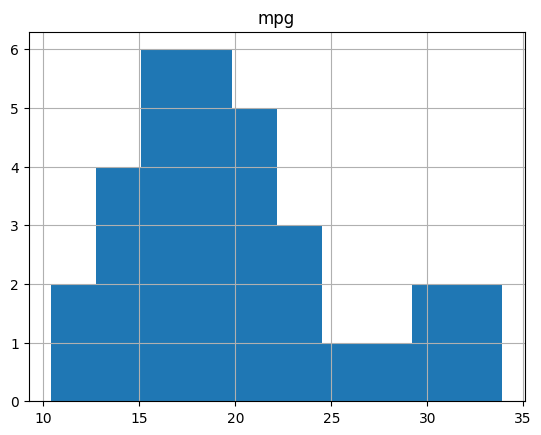

In [31]:
mtcars_mpg.hist();

Add the arguments `bins =` inside the `hist()` function if you want to
change the number of bins. A rule of thumb (known as Sturges’ law) is
that the number of bins should be the rounded value of the square root
of the number of observations. The dataset includes 32 observations so
in this case the number of bins can be set to 6.

array([[<Axes: title={'center': 'mpg'}>]], dtype=object)

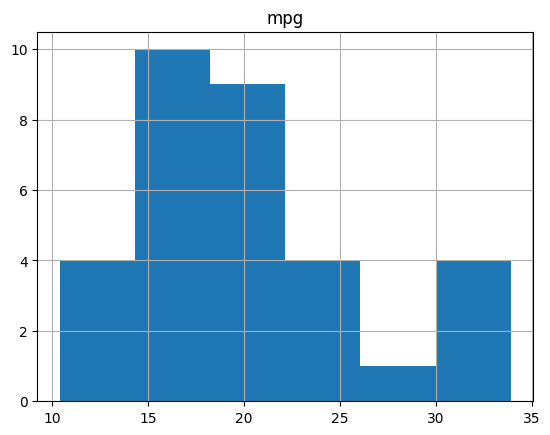

In [32]:
mtcars_mpg.hist(bins=6)

We can also use the `matplotlib` library to get a more customizable and visually appealing histogram. A `matplotlib` consists of a figure (`fig`), axes (`ax`), the plot itself, and some instructions to customize the plot to your liking. In a future lecture we will go into the details of creating beautiful plots with `matplotlib`, as well with the superlibrary `seaborn`, which is built on top of `matplotlib`.

One difference between `ggplot` and `matplotlib` is that in `ggplot` we can construct a plot in steps, while in `matplotlib` it's not possible.

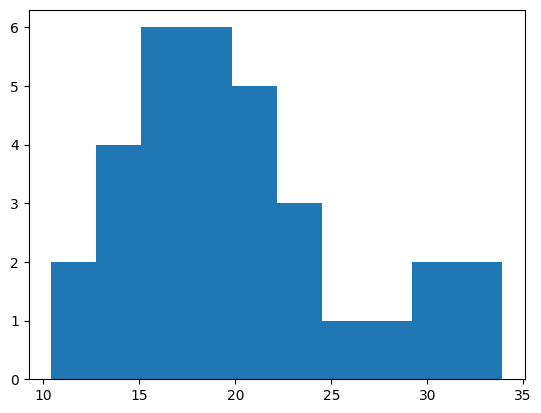

In [33]:
fig, ax = plt.subplots()
ax.hist(mtcars_mpg)
plt.show()

By default, the number of bins is 10. You can change this value with the argument `bins`. We can also use `edgecolor` for the bar outline color and `color` for filling in the bars.

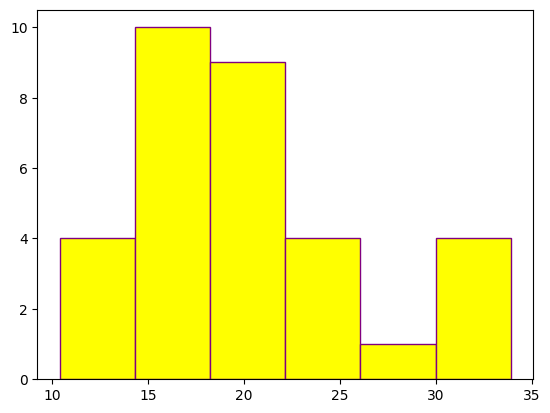

In [34]:
fig, ax = plt.subplots()
ax.hist(mtcars_mpg, bins = 6, edgecolor = 'purple', color = 'yellow')
plt.show()

We can draw the distribution shape on top of the histogram, plus some
options to beautify the plot, by using the `seaborn` library.

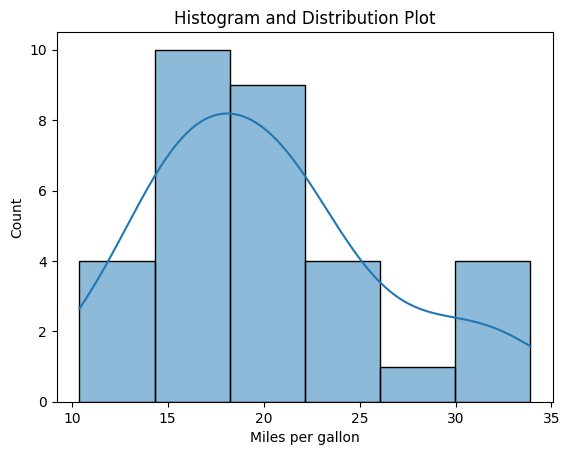

In [36]:
mpg_histogram = sns.histplot(mtcars_mpg, bins = 6, kde = True, legend = False);
mpg_histogram.set(title = 'Histogram and Distribution Plot', xlabel = 'Miles per gallon');
plt.show()

### Boxplots

Boxplots are really useful in descriptive statistics and are often
underused (mostly because it is not well understood by the public). A
boxplot graphically represents the distribution of a quantitative
variable by visually displaying five common location summary (minimum,
median, first/third quartiles and maximum) and any observation that was
classified as a suspected
[outlier](http://localhost:6653/blog/outliers-detection-in-r/) using the
interquartile range (IQR) criterion.

The IQR criterion means that all observations above
$q_{0.75}+1.5\cdot IQR$ or below $q_{0.25}-1.5\cdot IQR$ (where
$q_{0.25}$ and $q_{0.75}$ correspond to first and third quartile
respectively) are considered as potential outliers by R. The minimum and
maximum in the boxplot are represented without these suspected outliers.

Seeing all these information on the same plot help to have a good first
overview of the dispersion and the location of the data. Before drawing
a boxplot of our data, see below a graph explaining the information
present on a boxplot:

<figure>
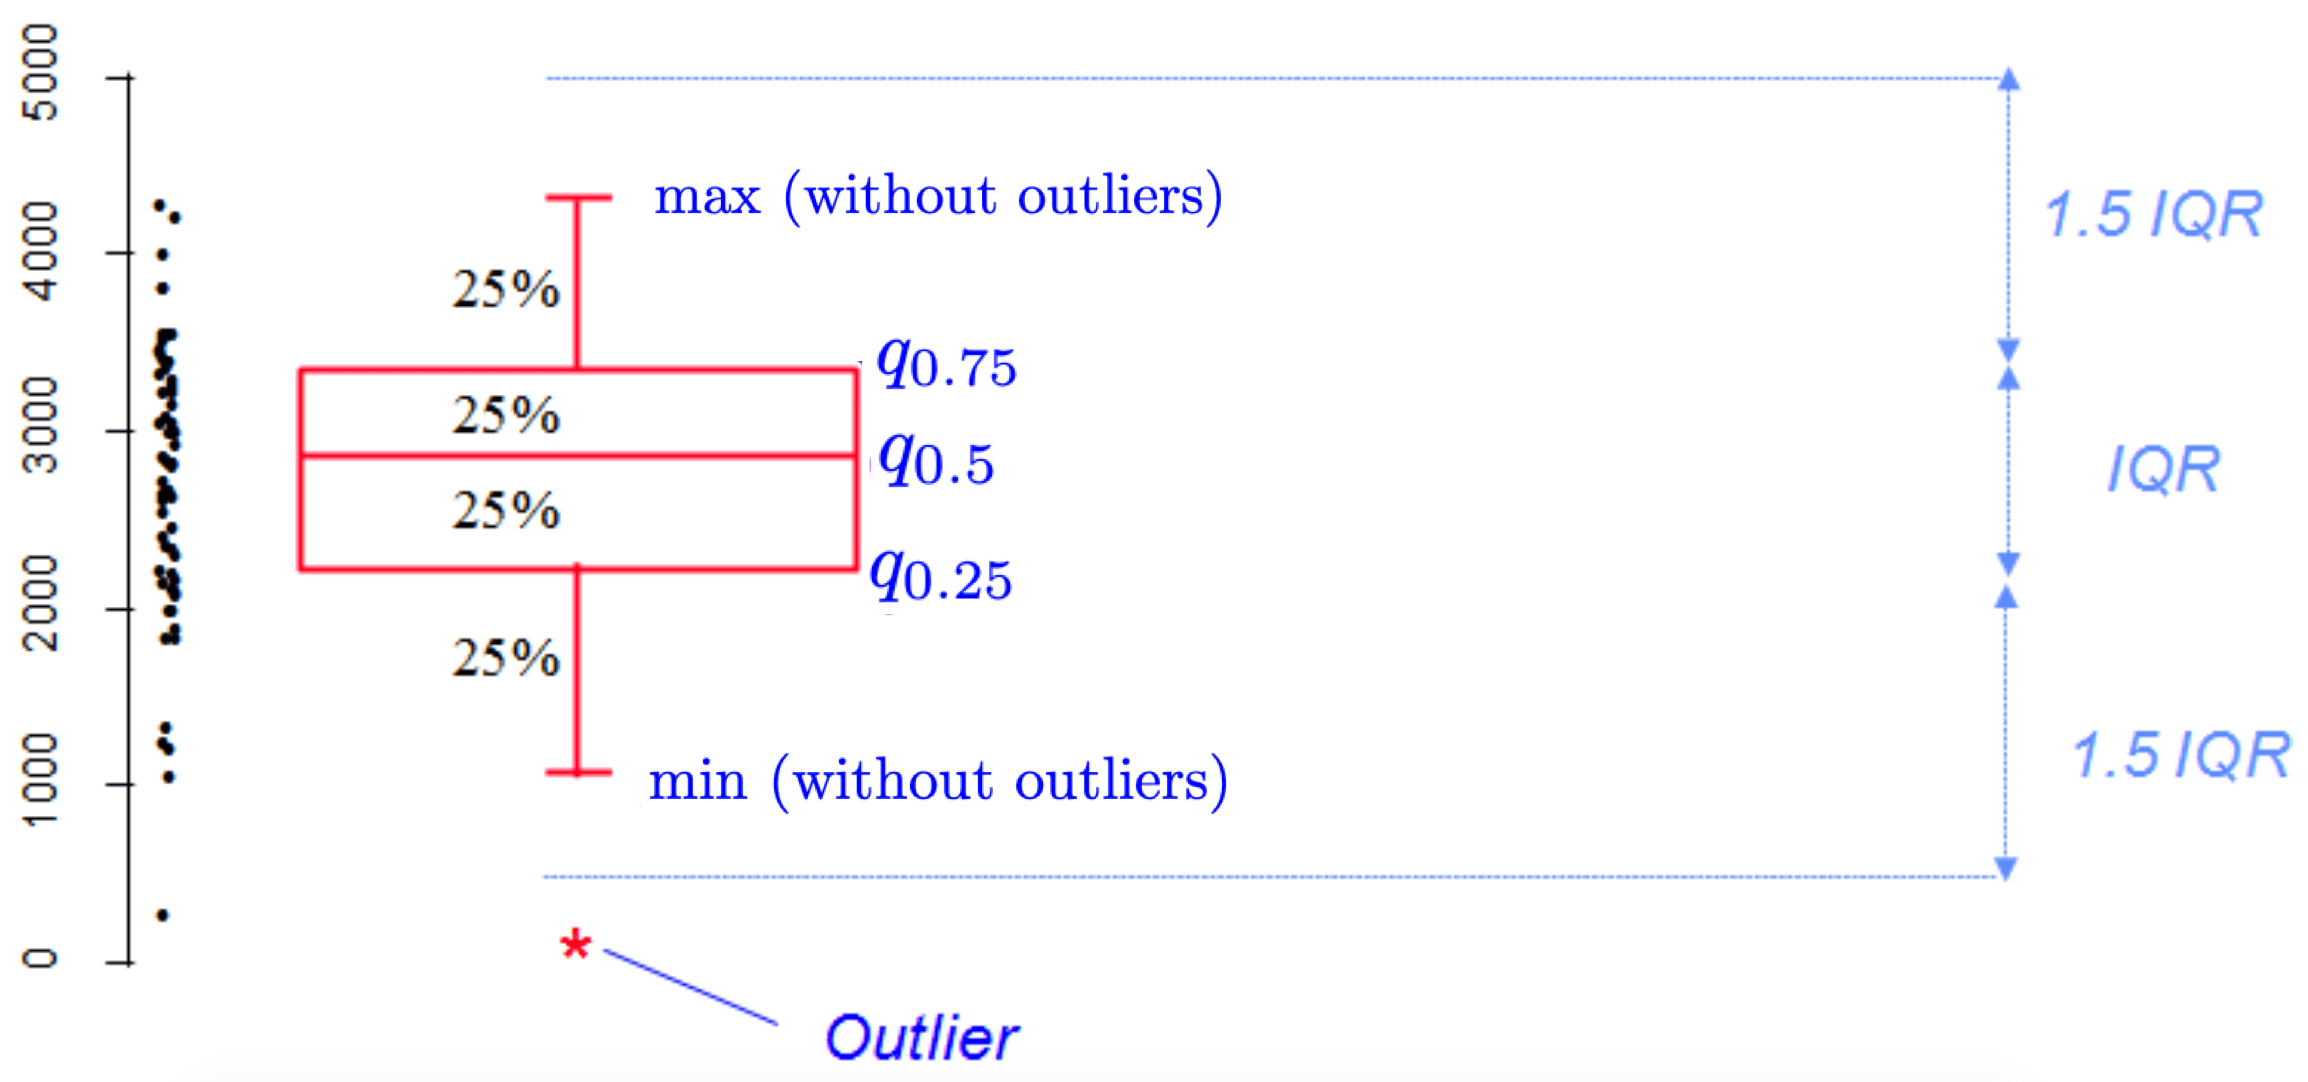
<figcaption aria-hidden="true">How to interpret a boxplot? Source:
LFSAB1105</figcaption>
</figure>

Now, an simple boxplot example with our data set.

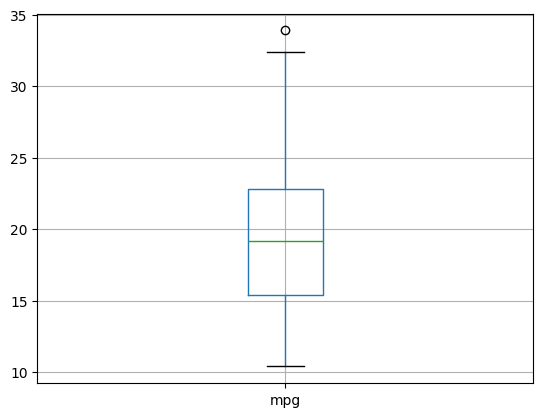

In [38]:
mtcars_mpg.boxplot();

The same boxplot, but now with `matplotlib`.

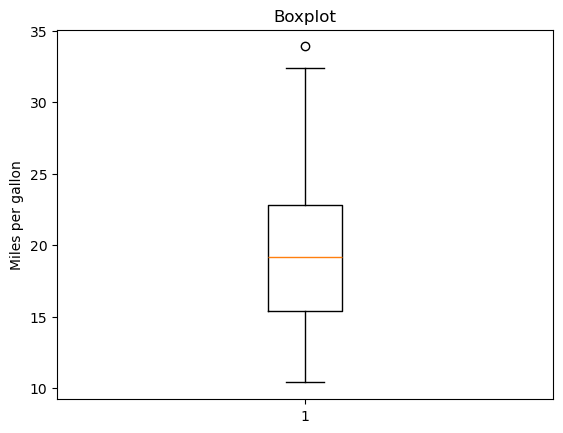

In [35]:
fig, ax = plt.subplots()
ax.boxplot(mtcars_mpg);
ax.set(title = 'Boxplot', xlabel = '', ylabel = 'Miles per gallon')
plt.show()

And a horizontal boxplot with `seaborn`.

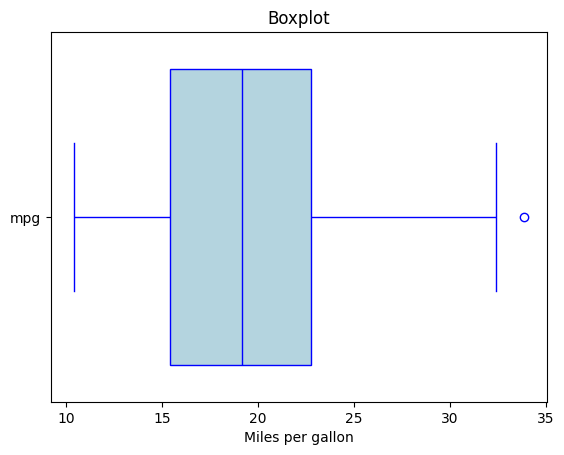

In [40]:
fig, ax = plt.subplots()
sns.boxplot(mtcars_mpg, color = 'LightBlue', linecolor = 'blue', orient = 'h')
ax.set(title = 'Boxplot', xlabel = 'Miles per gallon')
plt.show()

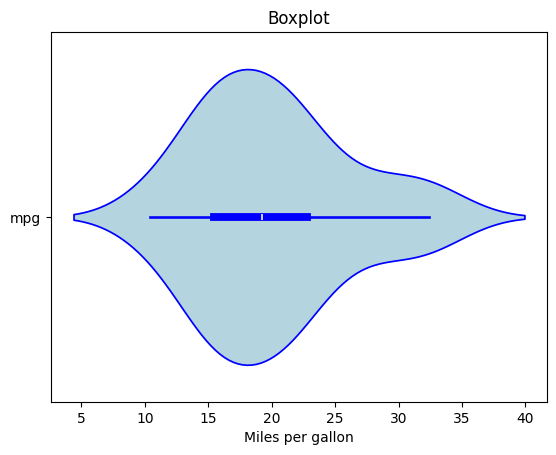

In [41]:
fig, ax = plt.subplots()
sns.violinplot(mtcars_mpg, color = 'LightBlue', linecolor = 'blue', orient = 'h')
ax.set(title = 'Violinplot', xlabel = 'Miles per gallon')
plt.show()